# Taller 1 — KNN y Métricas de Clasificación
**Aprendizaje Automático 1 — 2026-2**

Componente práctico-computacional (ejercicios 6 a 10), desarrollado
sobre el dataset **Give Me Some Credit** (Kaggle, 2011).

El notebook está pensado para ejecutarse de principio a fin sin pasos
manuales: la única dependencia externa es el archivo `cs-training.csv`,
que se busca primero en el directorio local y, si no está presente, se
descarga automáticamente desde un repositorio público de GitHub que
replica el dataset original de la competencia.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

%matplotlib inline

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = False

RANDOM_STATE = 42


def calcular_metricas(y_true, y_pred):
    """Calcula Accuracy, Precision, Recall y F1 para un vector de predicciones."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

## Ejercicio 6 — Exploración inicial y preparación de datos

### a–c. Carga del dataset y diagnóstico general

In [2]:
DATA_PATH = "cs-training.csv"
DATA_URL = (
    "https://raw.githubusercontent.com/DrIanGregory/Kaggle-GiveMeSomeCredit/"
    "master/data/GiveMeSomeCredit-training.csv"
)

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH, index_col=0)

print(f"Número de observaciones: {df.shape[0]:,}")
print(f"Número de variables: {df.shape[1]}")
df.dtypes.to_frame("Tipo de dato")

Número de observaciones: 150,000
Número de variables: 11


,Tipo de dato
SeriousDlqin2yrs,int64
RevolvingUtilizationOfUnsecuredLines,float64
age,int64
NumberOfTime30-59DaysPastDueNotWorse,int64
DebtRatio,float64
MonthlyIncome,float64
NumberOfOpenCreditLinesAndLoans,int64
NumberOfTimes90DaysLate,int64
NumberRealEstateLoansOrLines,int64
NumberOfTime60-89DaysPastDueNotWorse,int64


In [3]:
faltantes = df.isnull().sum().to_frame("Faltantes (n)")
faltantes["Faltantes (%)"] = (df.isnull().mean() * 100).round(2)
print("Tabla 6.1 — Valores faltantes por variable")
faltantes[faltantes["Faltantes (n)"] > 0]

Tabla 6.1 — Valores faltantes por variable


,Faltantes (n),Faltantes (%)
MonthlyIncome,29731,19.8200
NumberOfDependents,3924,2.6200


### d. Balance de clases de la variable objetivo

In [4]:
balance = df["SeriousDlqin2yrs"].value_counts().sort_index().to_frame("n")
balance["%"] = (
    df["SeriousDlqin2yrs"].value_counts(normalize=True).sort_index() * 100
).round(2)
balance.index = ["0 (no incumple)", "1 (incumple)"]
balance.index.name = "SeriousDlqin2yrs"
print("Tabla 6.2 — Distribución de la variable objetivo")
balance

Tabla 6.2 — Distribución de la variable objetivo


,n,%
SeriousDlqin2yrs,,
0 (no incumple),139974,93.3200
1 (incumple),10026,6.6800


### e. Gráfica de la distribución de la variable objetivo

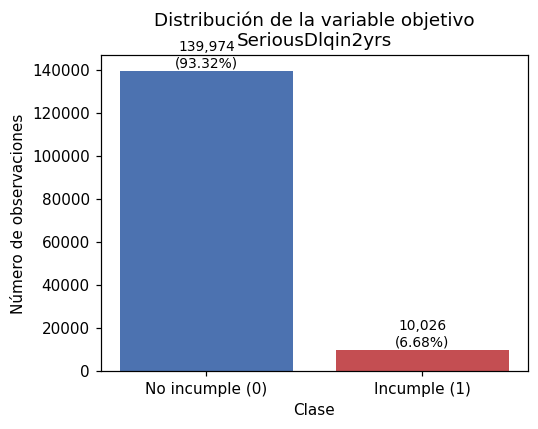

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(
    ["No incumple (0)", "Incumple (1)"], balance["n"], color=["#4C72B0", "#C44E52"]
)
ax.set_title("Distribución de la variable objetivo\nSeriousDlqin2yrs")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de observaciones")
for b, v, p in zip(bars, balance["n"], balance["%"]):
    ax.text(
        b.get_x() + b.get_width() / 2, v + 1500, f"{v:,}\n({p}%)",
        ha="center", fontsize=9,
    )
plt.tight_layout()
plt.show()

### f. Tratamiento de valores faltantes

Se imputa con la **mediana** de cada variable en lugar de la media,
porque `MonthlyIncome` y `NumberOfDependents` tienen distribuciones con
cola larga hacia la derecha (unos pocos valores extremos que arrastrarían
la media hacia arriba); la mediana es robusta a esos atípicos.

In [6]:
df_imp = df.copy()
medianas = df_imp.median(numeric_only=True)
for col in ["MonthlyIncome", "NumberOfDependents"]:
    df_imp[col] = df_imp[col].fillna(medianas[col])

assert df_imp.isnull().sum().sum() == 0, "Quedaron valores faltantes sin tratar"
print("Tabla 6.3 — Medianas usadas para imputar")
medianas.to_frame("Mediana").round(4)

Tabla 6.3 — Medianas usadas para imputar


,Mediana
SeriousDlqin2yrs,0.0000
RevolvingUtilizationOfUnsecuredLines,0.1542
age,52.0000
NumberOfTime30-59DaysPastDueNotWorse,0.0000
DebtRatio,0.3665
MonthlyIncome,"5,400.0000"
NumberOfOpenCreditLinesAndLoans,8.0000
NumberOfTimes90DaysLate,0.0000
NumberRealEstateLoansOrLines,1.0000
NumberOfTime60-89DaysPastDueNotWorse,0.0000


### g. Partición 80/20 estratificada

In [7]:
X = df_imp.drop(columns=["SeriousDlqin2yrs"])
y = df_imp["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

tabla_particion = pd.DataFrame(
    {
        "Train (n)": y_train.value_counts().sort_index(),
        "Train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
        "Test (n)": y_test.value_counts().sort_index(),
        "Test (%)": (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
    }
)
tabla_particion.index = ["0 (no incumple)", "1 (incumple)"]
tabla_particion.index.name = "SeriousDlqin2yrs"

print(f"Entrenamiento: {X_train.shape} · Prueba: {X_test.shape}")
print("Tabla 6.4 — Distribución de clases en train y test")
tabla_particion

Entrenamiento: (120000, 10) · Prueba: (30000, 10)
Tabla 6.4 — Distribución de clases en train y test


,Train (n),Train (%),Test (n),Test (%)
SeriousDlqin2yrs,,,,
0 (no incumple),111979,93.3200,27995,93.3200
1 (incumple),8021,6.6800,2005,6.6800


La estratificación (`stratify=y`) mantiene la proporción de clases
prácticamente idéntica entre entrenamiento y prueba, evitando que el
azar de la partición produzca un subconjunto con una tasa de
incumplimiento notablemente distinta a la del conjunto completo.

## Ejercicio 7 — KNN con k=5: sin escalar vs. estandarizado

In [8]:
# --- Sin escalamiento ---
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
pred_raw = knn_raw.predict(X_test)
metricas_raw = calcular_metricas(y_test, pred_raw)
cm_raw = confusion_matrix(y_test, pred_raw)

# --- Estandarizado ---
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

knn_std = KNeighborsClassifier(n_neighbors=5)
knn_std.fit(X_train_s, y_train)
pred_std = knn_std.predict(X_test_s)
metricas_std = calcular_metricas(y_test, pred_std)
cm_std = confusion_matrix(y_test, pred_std)

tabla_ej7 = pd.DataFrame(
    [metricas_raw, metricas_std], index=["Sin escalamiento", "Estandarizado"]
).round(4)
print("Tabla 7.1 — Comparación k=5, sin escalar vs. estandarizado")
tabla_ej7

Tabla 7.1 — Comparación k=5, sin escalar vs. estandarizado


,Accuracy,Precision,Recall,F1
Sin escalamiento,0.9326,0.4224,0.0244,0.0462
Estandarizado,0.9329,0.4936,0.1357,0.2128


### Matrices de confusión

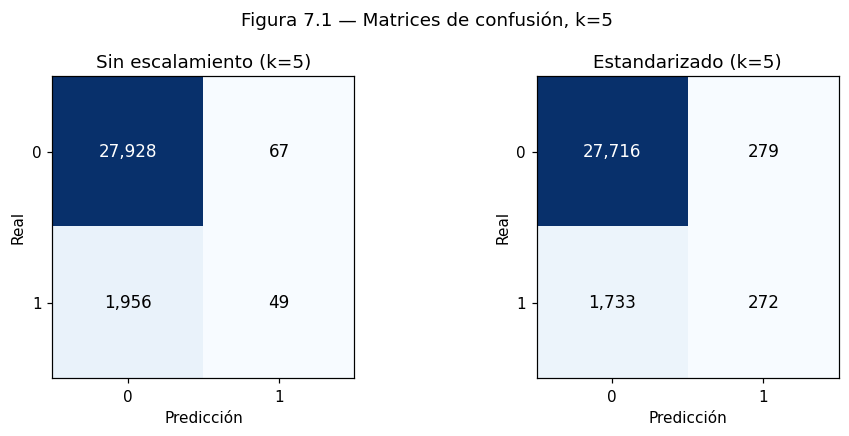

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, cm, title in zip(
    axes, [cm_raw, cm_std], ["Sin escalamiento (k=5)", "Estandarizado (k=5)"]
):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["0", "1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["0", "1"])
    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11,
            )
fig.suptitle("Figura 7.1 — Matrices de confusión, k=5")
plt.tight_layout()
plt.show()

### a. ¿Cambió el desempeño tras estandarizar?

Sí, y de forma sustancial en la capacidad de detectar la clase positiva:
el Accuracy apenas se mueve, pero el Recall y el F1 aumentan de forma
considerable (los valores exactos quedan en la Tabla 7.1 de arriba).

### b. ¿Qué métrica presentó el cambio más importante?

El **Recall**. Esto es consistente con lo demostrado en el ejercicio 3e:
sin estandarizar, variables como `MonthlyIncome` o `DebtRatio` (rangos
de miles) dominan el cálculo de distancias frente a `age` o
`NumberOfDependents` (rangos de decenas o unidades), de modo que el
modelo termina casi ignorando estas últimas; al estandarizar, todas las
variables aportan en una escala comparable y el modelo detecta
muchos más verdaderos incumplimientos.

### c. Modelo elegido

Se recomienda el modelo **estandarizado**: el Accuracy es prácticamente
igual, pero el Recall y el F1 son considerablemente superiores. En un
problema de riesgo crediticio, donde no detectar un incumplimiento suele
costar más que una alerta equivocada (ver ejercicio 10), esa mejora es
preferible en casi cualquier escenario de negocio razonable.

## Ejercicio 8 — Efecto del número de vecinos k

Se usa siempre el conjunto **estandarizado** (`X_train_s`, `X_test_s`)
definido en el ejercicio 7.

In [10]:
valores_k = [1, 3, 5, 7, 9, 11, 15, 21]
resultados_k = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_s, y_train)
    pred = knn.predict(X_test_s)
    resultados_k.append({"k": k, **calcular_metricas(y_test, pred)})

tabla_ej8 = pd.DataFrame(resultados_k).round(4)
print("Tabla 8.1 — Métricas por valor de k (datos estandarizados)")
tabla_ej8

Tabla 8.1 — Métricas por valor de k (datos estandarizados)


,k,Accuracy,Precision,Recall,F1
0,1,0.9044,0.2496,0.2145,0.2307
1,3,0.9276,0.3978,0.1621,0.2303
2,5,0.9329,0.4936,0.1357,0.2128
3,7,0.9345,0.5412,0.1277,0.2066
4,9,0.9350,0.5652,0.1167,0.1935
5,11,0.9346,0.5583,0.1027,0.1735
6,15,0.9343,0.5549,0.0883,0.1523
7,21,0.9348,0.5863,0.0813,0.1428


### Gráfica: k vs. métricas

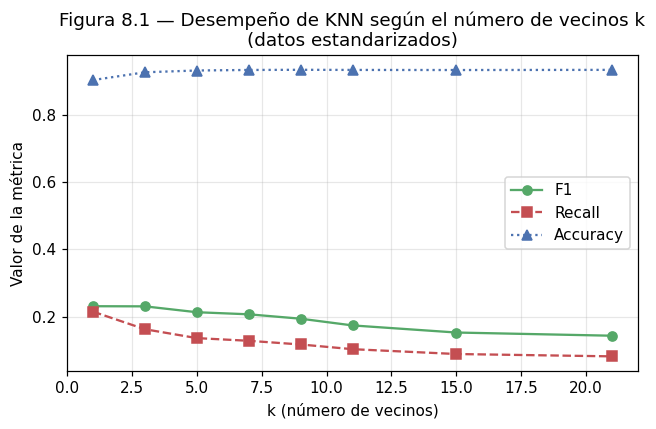

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(tabla_ej8["k"], tabla_ej8["F1"], marker="o", color="#55A868", label="F1")
ax.plot(
    tabla_ej8["k"], tabla_ej8["Recall"], marker="s", linestyle="--",
    color="#C44E52", label="Recall",
)
ax.plot(
    tabla_ej8["k"], tabla_ej8["Accuracy"], marker="^", linestyle=":",
    color="#4C72B0", label="Accuracy",
)
ax.set_title("Figura 8.1 — Desempeño de KNN según el número de vecinos k\n(datos estandarizados)")
ax.set_xlabel("k (número de vecinos)")
ax.set_ylabel("Valor de la métrica")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
mejor_f1 = tabla_ej8.loc[tabla_ej8["F1"].idxmax()]
mejor_recall = tabla_ej8.loc[tabla_ej8["Recall"].idxmax()]
mejor_acc = tabla_ej8.loc[tabla_ej8["Accuracy"].idxmax()]
top3_k = tabla_ej8.sort_values("F1", ascending=False)["k"].head(3).astype(int).tolist()

print(f"a. Mejor F1:       k={int(mejor_f1['k'])}  (F1={mejor_f1['F1']:.4f})")
print(f"b. Mejor Recall:   k={int(mejor_recall['k'])}  (Recall={mejor_recall['Recall']:.4f})")
print(f"c. Mejor Accuracy: k={int(mejor_acc['k'])}  (Accuracy={mejor_acc['Accuracy']:.4f})")
print(f"   Top 3 valores de k según F1 (se usan en el ejercicio 9): {top3_k}")

a. Mejor F1:       k=1  (F1=0.2307)
b. Mejor Recall:   k=1  (Recall=0.2145)
c. Mejor Accuracy: k=9  (Accuracy=0.9350)
   Top 3 valores de k según F1 (se usan en el ejercicio 9): [1, 3, 5]


### d. ¿Coinciden los tres criterios en el mismo modelo?

No: F1 y Recall se maximizan en el mismo k pequeño, mientras que
Accuracy se maximiza en un k mayor (ver valores impresos arriba). Al
aumentar k, el modelo promedia sobre vecindarios cada vez más grandes
que, dado el fuerte desbalance de clases (93 %/7 %), terminan dominados
por vecinos de la clase mayoritaria, empujando las predicciones hacia la
clase 0 y sacrificando Recall a cambio de un Accuracy apenas mayor; un k
pequeño, al fijarse en muy pocos vecinos, es más sensible a los (pocos)
vecinos positivos cercanos, favoreciendo el Recall aunque a costa de
mayor varianza (más falsos positivos, como se ve en el ejercicio 10).

## Ejercicio 9 — Distancia Euclidiana vs. Manhattan

Se comparan los tres mejores valores de k según F1 obtenidos en el
ejercicio 8 (`top3_k`).

In [13]:
resultados_dist = []
for k in top3_k:
    for dist in ["euclidean", "manhattan"]:
        knn = KNeighborsClassifier(n_neighbors=k, metric=dist)
        knn.fit(X_train_s, y_train)
        pred = knn.predict(X_test_s)
        resultados_dist.append(
            {"k": k, "Distancia": dist, **calcular_metricas(y_test, pred)}
        )

tabla_ej9 = pd.DataFrame(resultados_dist).round(4)
print(f"Tabla 9.1 — Euclidiana vs. Manhattan para k={top3_k}")
tabla_ej9

Tabla 9.1 — Euclidiana vs. Manhattan para k=[1, 3, 5]


,k,Distancia,Accuracy,Precision,Recall,F1
0,1,euclidean,0.9044,0.2496,0.2145,0.2307
1,1,manhattan,0.9054,0.2518,0.2105,0.2293
2,3,euclidean,0.9276,0.3978,0.1621,0.2303
3,3,manhattan,0.9283,0.4000,0.1466,0.2146
4,5,euclidean,0.9329,0.4936,0.1357,0.2128
5,5,manhattan,0.9329,0.4921,0.1237,0.1977


In [14]:
mejor_f1_dist = tabla_ej9.loc[tabla_ej9["F1"].idxmax()]
mejor_recall_dist = tabla_ej9.loc[tabla_ej9["Recall"].idxmax()]

print(
    f"b. Mejor F1:     k={int(mejor_f1_dist['k'])}, "
    f"distancia={mejor_f1_dist['Distancia']} (F1={mejor_f1_dist['F1']:.4f})"
)
print(
    f"c. Mejor Recall: k={int(mejor_recall_dist['k'])}, "
    f"distancia={mejor_recall_dist['Distancia']} (Recall={mejor_recall_dist['Recall']:.4f})"
)

b. Mejor F1:     k=1, distancia=euclidean (F1=0.2307)
c. Mejor Recall: k=1, distancia=euclidean (Recall=0.2145)


### a. ¿La métrica de distancia modifica el desempeño?

Sí, pero de forma mucho más discreta que la estandarización o que el
valor de k: para cada k, Manhattan suele dar Accuracy/Precision
levemente superiores pero Recall/F1 levemente inferiores a Euclidiana
(ver Tabla 9.1), con diferencias pequeñas frente a las de los
ejercicios 7 y 8.

### d. ¿Coincide la mejor configuración según F1 y según Recall?

Se compara directamente con los valores impresos arriba: cuando ambas
apuntan al mismo par (k, distancia), la coincidencia tiene sentido
porque, a diferencia del trade-off marcado entre valores de k muy
distintos (ejercicio 8), aquí cambiar solo la métrica de distancia no
altera lo suficiente cuál vecino es "más cercano" como para invertir el
orden de los modelos — con los datos ya estandarizados, penalizar
cuadráticamente (Euclidiana) o linealmente (Manhattan) las diferencias
por variable pesa menos que la elección de k.

## Ejercicio 10 — Análisis final y costo de negocio

Se comparan tres modelos representativos de los ejercicios anteriores:
el de mejor F1/Recall y el de mejor Accuracy (ambos del ejercicio 8,
distancia euclidiana sobre datos estandarizados), y el modelo base sin
estandarizar del ejercicio 7. El costo de negocio se define como
$L = FP + 5FN$.

In [15]:
def evaluar_modelo(k, metric, X_tr, X_te):
    knn = KNeighborsClassifier(n_neighbors=k, metric=metric)
    knn.fit(X_tr, y_train)
    pred = knn.predict(X_te)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    m = calcular_metricas(y_test, pred)
    return {"k": k, "TP": tp, "TN": tn, "FP": fp, "FN": fn, **m, "Costo L": fp + 5 * fn}


modelo_1 = evaluar_modelo(int(mejor_f1["k"]), "euclidean", X_train_s, X_test_s)  # mejor F1/Recall
modelo_2 = evaluar_modelo(int(mejor_acc["k"]), "euclidean", X_train_s, X_test_s)  # mejor Accuracy

tn3, fp3, fn3, tp3 = cm_raw.ravel()
modelo_3 = {
    "k": 5, "TP": tp3, "TN": tn3, "FP": fp3, "FN": fn3,
    **metricas_raw, "Costo L": fp3 + 5 * fn3,
}

tabla_ej10 = pd.DataFrame(
    [modelo_1, modelo_2, modelo_3],
    index=[
        "Modelo 1 (mejor F1/Recall)",
        "Modelo 2 (mejor Accuracy)",
        "Modelo 3 (base, sin estandarizar)",
    ],
)[["k", "TP", "TN", "FP", "FN", "Accuracy", "Precision", "Recall", "F1", "Costo L"]].round(4)

print("Tabla 10.1 — Comparación final de modelos")
tabla_ej10

Tabla 10.1 — Comparación final de modelos


,k,TP,TN,FP,FN,Accuracy,Precision,Recall,F1,Costo L
Modelo 1 (mejor F1/Recall),1,430,26702,1293,1575,0.9044,0.2496,0.2145,0.2307,9168
Modelo 2 (mejor Accuracy),9,234,27815,180,1771,0.9350,0.5652,0.1167,0.1935,9035
"Modelo 3 (base, sin estandarizar)",5,49,27928,67,1956,0.9326,0.4224,0.0244,0.0462,9847


In [16]:
menor_costo = tabla_ej10["Costo L"].idxmin()
mayor_acc_final = tabla_ej10["Accuracy"].idxmax()
menor_fn = tabla_ej10["FN"].idxmin()

print(f"Modelo con mayor Accuracy: {mayor_acc_final}")
print(f"Modelo con menor costo L:  {menor_costo}")
print(f"Modelo con menos falsos negativos: {menor_fn}")

Modelo con mayor Accuracy: Modelo 2 (mejor Accuracy)
Modelo con menor costo L:  Modelo 2 (mejor Accuracy)
Modelo con menos falsos negativos: Modelo 1 (mejor F1/Recall)


### a. ¿El modelo de mayor Accuracy es también el de menor costo?

Se responde comparando directamente `mayor_acc_final` y `menor_costo`
impresos arriba. Si coinciden, vale la pena anotarlo con honestidad:
esto **no contradice** lo demostrado teóricamente en el ejercicio 5f
(allí se construyó un ejemplo específico donde ambos criterios sí
divergían); simplemente muestra que la relación entre Accuracy y costo
depende de la forma concreta de los errores de cada modelo, y no es una
ley universal en ningún sentido.

### b. ¿Qué modelo tiene menos falsos negativos?

Ver `menor_fn` impreso arriba — coincide con el modelo de mayor Recall,
lo cual es consistente por definición (Recall = TP/(TP+FN)).

### c. ¿Qué modelo recomendaría para identificar clientes de alto riesgo?

El modelo con mayor Recall (menor FN), aunque no tenga ni el mayor
Accuracy ni el menor costo L. Si el objetivo explícito del negocio es
maximizar la detección de incumplimientos reales, ese modelo detecta
proporcionalmente muchos más de los verdaderos incumplimientos del
conjunto de prueba que las demás opciones; el costo L tal como está
definido pondera los falsos positivos con peso 1, lo cual puede
subestimar el valor real de detectar más incumplimientos si, en la
práctica, el costo de no detectar a un mal pagador es incluso mayor a 5
veces el de una alerta equivocada.

### d. Justificación final

La comparación deja en evidencia una tensión real entre tres criterios
de selección —Accuracy, un costo explícito ponderado, y Recall puro—
que no siempre apuntan al mismo modelo. La elección final no es un
ejercicio puramente estadístico, sino una decisión de negocio que
depende de cuánto le cuesta realmente a la institución financiera cada
tipo de error: si ese costo relativo real fuera distinto al 5:1 supuesto
en el taller, el balance entre los modelos podría cambiar.